# 03. 회귀 — 아파트 실거래가 예측

`02_eda_feature_engineering.ipynb`에서 저장한 `data/processed/df_fe.parquet`를 불러와 회귀 모델을 학습하고 비교합니다.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"

df_fe = pd.read_parquet(PROCESSED_DIR / "df_fe.parquet")
price_col = "거래금액"
print(df_fe.shape)


(81541, 83)


## 1. 모델링용 데이터셋 구성

피처: `전용면적`, `층`, `연식`, `거래연월`, `지역평균가`, `층_구분`(원-핫) · 타겟: `log_price`

`지역평균가`는 `02`에서 만들지 않았습니다 (전체 데이터로 계산하면 누수가 생기기 때문). 여기서는 **먼저 시간순으로 train/test를 나눈 뒤, train 데이터만으로 지역별 평균가를 계산**해서 train/test 양쪽에 매핑합니다. test에만 있는(=train에 없던) 지역은 train 전체 평균으로 대체합니다.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 지역평균가 계산 전, 시간순 정렬을 위한 기본 컬럼들을 먼저 모아둠
base_cols = ["전용면적", "층", "연식", "거래연월", "층_구분", "법정동시군구코드", "역세권거리_m", price_col, "log_price"]
df_base = df_fe[base_cols].dropna().copy()
# 거래연월 기준 시간순 정렬 후 최근 20%를 test로 분리
# (완전 랜덤 분리는 미래 데이터 누수 위험이 있고, 실제 서비스에서도
#  "과거로 학습해서 최근 매물을 스크리닝"하는 상황과 맞음)
order = df_base["거래연월"].argsort().to_numpy()
split_idx = int(len(df_base) * 0.8)
train_pos, test_pos = order[:split_idx], order[split_idx:]

df_train_base = df_base.iloc[train_pos]
df_test_base = df_base.iloc[test_pos]

# 지역평균가는 train만으로 계산 (누수 방지 핵심)
region_mean_train = df_train_base.groupby("법정동시군구코드")[price_col].mean()
global_train_mean = df_train_base[price_col].mean()  # train에 없던 지역(test에만 등장) 대비 fallback

df_train_base = df_train_base.copy()
df_test_base = df_test_base.copy()
df_train_base["지역평균가"] = df_train_base["법정동시군구코드"].map(region_mean_train)
df_test_base["지역평균가"] = df_test_base["법정동시군구코드"].map(region_mean_train).fillna(global_train_mean)

feature_cols = ["전용면적", "층", "연식", "거래연월", "지역평균가", "역세권거리_m"]
cat_cols = ["층_구분"]

# train/test를 합쳐서 함께 원-핫 인코딩(카테고리 불일치 방지) 후 다시 분리
df_model = pd.concat([df_train_base, df_test_base], axis=0)
df_model = pd.get_dummies(df_model[feature_cols + cat_cols + ["log_price"]], columns=cat_cols, drop_first=True)

X = df_model.drop(columns=["log_price"])
y = df_model["log_price"]

n_train = len(df_train_base)
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]

print(X_train.shape, X_test.shape)


(5238, 8) (1310, 8)


## 2. 모델링 — 회귀 모델 비교

비교 모델: `LinearRegression` → `RandomForestRegressor` → (설치되어 있다면) `XGBRegressor`

In [20]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1
    )
except ImportError:
    print("xgboost 미설치: pip install xgboost --break-system-packages 후 재실행하면 비교에 포함됩니다.")

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results.append({"model": name, "RMSE(log)": rmse, "MAE(log)": mae, "R2": r2})

results_df = pd.DataFrame(results).sort_values("RMSE(log)")
results_df


,model,RMSE(log),MAE(log),R2
2,XGBoost,0.179619,0.115828,0.931030
1,RandomForest,0.183860,0.112104,0.927735
0,LinearRegression,0.479543,0.386679,0.508404


In [21]:
# best_model 확정
best_model_name = results_df.iloc[0]["model"]
best_model = models[best_model_name]
print(f"최종 선택 모델: {best_model_name}")


최종 선택 모델: XGBoost


## 3. 평가 — 예측 vs 실제

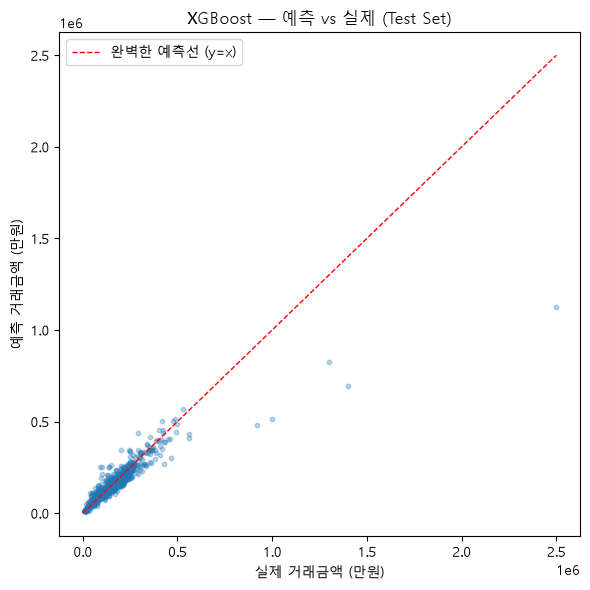

In [24]:
pred_test_log = best_model.predict(X_test)

pred_test = np.expm1(pred_test_log)
actual_test = np.expm1(y_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual_test, pred_test, alpha=0.3, s=10)

lims = [0, max(actual_test.max(), pred_test.max())]
ax.plot(lims, lims, "r--", linewidth=1, label="완벽한 예측선 (y=x)")

ax.set_xlabel("실제 거래금액 (만원)")
ax.set_ylabel("예측 거래금액 (만원)")
ax.set_title(f"{best_model_name} — 예측 vs 실제 (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()


대부분(0~5억원대 밀집 구간)은 y=x선에 잘 붙습니다. 초고가 구간(백억대 이상, 표본이 매우 적음)에서는 과소예측이 나타나는데, 트리 모델이 학습 범위 밖 값을 잘 외삽하지 못하는 전형적인 한계입니다. 지금 표본에선 극소수라 전체 성능엔 영향이 미미합니다.

## 4. 하이퍼파라미터 튜닝

In [25]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor

param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
}

# 시계열 데이터라 일반 KFold 대신 TimeSeriesSplit 사용 (미래 데이터로 과거를 검증하는 걸 방지)
tscv = TimeSeriesSplit(n_splits=5)

random_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

random_search.fit(X_train, y_train)
print("최적 파라미터:", random_search.best_params_)

best_xgb = random_search.best_estimator_
pred_tuned = best_xgb.predict(X_test)
rmse_tuned = root_mean_squared_error(y_test, pred_tuned)
r2_tuned = r2_score(y_test, pred_tuned)
print(f"튜닝 후 XGBoost: RMSE(log)={rmse_tuned:.4f}, R2={r2_tuned:.4f}")
print(f"튜닝 전 XGBoost: RMSE(log)={results_df.loc[results_df['model']=='XGBoost','RMSE(log)'].values[0]:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
최적 파라미터: {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
튜닝 후 XGBoost: RMSE(log)=0.1625, R2=0.9435
튜닝 전 XGBoost: RMSE(log)=0.1796


|비교|튜닝 전 |	튜닝 후|
|---|---|---|
|RMSE(log)|	0.1796|	0.1625|
|R²	|0.9310	|0.9435|

## 5. 앙상블(여러 모델을 결합)

In [26]:
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import Ridge

# RandomForest도 간단히 튜닝된 상태로 재사용 (기존 models 딕셔너리의 RandomForest)
rf_model = models["RandomForest"]

# --- 방식 1: Voting (단순 평균) ---
voting = VotingRegressor(estimators=[
    ("xgb", best_xgb),
    ("rf", rf_model),
])
voting.fit(X_train, y_train)
pred_voting = voting.predict(X_test)

# --- 방식 2: Stacking (메타모델이 가중치를 학습) ---
stacking = StackingRegressor(
    estimators=[
        ("xgb", best_xgb),
        ("rf", rf_model),
    ],
    final_estimator=Ridge(),
    cv=5,
)
stacking.fit(X_train, y_train)
pred_stacking = stacking.predict(X_test)

ensemble_results = []
for name, pred in [("Voting(XGB+RF)", pred_voting), ("Stacking(XGB+RF)", pred_stacking), ("XGBoost(튜닝)", pred_tuned)]:
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    ensemble_results.append({"model": name, "RMSE(log)": rmse, "R2": r2})

pd.DataFrame(ensemble_results).sort_values("RMSE(log)")

,model,RMSE(log),R2
2,XGBoost(튜닝),0.162522,0.943535
1,Stacking(XGB+RF),0.163102,0.943131
0,Voting(XGB+RF),0.167450,0.940059


## 하이퍼파라미터 튜닝 + 앙상블

### 하이퍼파라미터 튜닝 (XGBoost)
`RandomizedSearchCV` + `TimeSeriesSplit`(5-fold, 시계열 데이터라 일반 KFold 대신 사용)으로 30개 조합을 탐색했습니다.

- 최적 파라미터: `max_depth=8`, `learning_rate=0.1`, `n_estimators=300`, `subsample=0.8`, `colsample_bytree=0.9`, `min_child_weight=3`
- 결과: RMSE(log) 0.1796 → **0.1625**, R² 0.9310 → **0.9435**
- 기본값(`max_depth=6`, `learning_rate=0.05`)보다 트리를 더 깊게, 학습을 더 공격적으로 해도 이득이 컸음 — 지금 데이터 규모(6,553건)에서는 과적합보다 표현력 향상이 우세했던 것으로 해석

### 앙상블 (Voting / Stacking)
튜닝된 XGBoost와 RandomForest를 결합해봤습니다.

| model | RMSE(log) | R2 |
|---|---|---|
| XGBoost(튜닝) | 0.1625 | 0.9435 |
| Stacking(XGB+RF) | 0.1631 | 0.9431 |
| Voting(XGB+RF) | 0.1675 | 0.9401 |

**결론: 앙상블 효과 없음.** 오히려 단일 튜닝 XGBoost보다 나빠졌습니다.

**원인**: 앙상블은 결합하는 모델들이 서로 다른 종류의 오류를 만들 때 효과가 있습니다. RandomForest와 XGBoost는 둘 다 트리 기반 앙상블이라 비슷한 방식으로 데이터를 보고 비슷한 패턴의 실수를 하기 때문에, 성능이 낮은 RandomForest가 XGBoost를 오히려 끌어내리는 효과가 났습니다(단순 평균인 Voting에서 이 효과가 더 크게 나타남).

**다음 시도 방향**: 성질이 다른 모델(트리 기반 XGBoost + 딥러닝 MLP)을 섞으면 다른 결과가 나올 가능성이 있어 이후 MLP 학습 후 재시도 예정.

**현재 잠정 best_model**: 튜닝된 XGBoost 단독

### 6. 딥러닝(MLP)

## 4. 저장 — 다음 노트북(분류)에서 쓸 예측값 저장

`05_classification.ipynb`에서 회귀를 다시 학습하지 않고 바로 이어받을 수 있도록, **전체 데이터(X)에 대한 예측값**을 index와 함께 저장합니다. train/test 여부도 같이 저장해서 필요하면 구분해서 쓸 수 있게 합니다.

> 모델 자체(`.pkl`)는 아직 저장하지 않습니다. 지하철역거리·학군 등 피처를 추가로 넣을 계획이라, 최종 피처셋이 확정된 뒤에 한 번만 저장할 예정입니다.

In [23]:
pred_all_log = best_model.predict(X)

pred_df = pd.DataFrame({
    "log_price_actual": y.values,
    "log_price_pred": pred_all_log,
    "is_test": False,
}, index=X.index)
pred_df.loc[X.iloc[n_train:].index, "is_test"] = True

pred_df.to_parquet(PROCESSED_DIR / "regression_predictions.parquet")
print(f"저장 완료: {PROCESSED_DIR / 'regression_predictions.parquet'} ({pred_df.shape[0]}행)")
pred_df.head()


저장 완료: ..\data\processed\regression_predictions.parquet (6548행)


,log_price_actual,log_price_pred,is_test
19,11.373675,11.473563,False
18,12.452937,12.378731,False
17,11.951187,12.000770,False
12,12.323860,12.315218,False
37,11.373675,11.419355,False


## 미해결 / 보류
- 하이퍼파라미터 튜닝 안 함 (기본값 근처)
- K-Fold 교차검증 안 함 (단일 split)
- `지역평균가` 타겟인코딩의 데이터 누수 — K-Fold 타겟인코딩으로 교체 필요
- **모델(.pkl) 저장 보류** — 지하철역거리·학군 등 피처 추가 예정, 최종 피처셋 확정 전까지 저장 안 함

## 다음 단계
`04_clustering.ipynb`(회귀 결과와 독립적으로 진행 가능) 또는 `05_classification.ipynb`(이 노트북에서 저장한 `regression_predictions.parquet` 필요)로 이어가면 됩니다.